# 01. Random Forest V3 - 60/40, 70/30, tiempo y validación R²

In [1]:
# ============================================================
# CRONÓMETRO GENERAL DEL NOTEBOOK
# ============================================================

import time

TIEMPO_INICIO_TOTAL_GENERAL = time.perf_counter()


## 1. Librerías

Ejecuta esta celda primero. Si falta alguna librería, instálala desde Anaconda Prompt o desde una celda de Jupyter con `!pip install nombre_libreria`.


In [2]:

import os
import warnings
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)



## 2. Rutas de trabajo

La carpeta base queda definida como la carpeta donde está el cuaderno. Si tus archivos están en otra ubicación, cambia `BASE_DIR`.


In [3]:

BASE_DIR = "."
OUT_DIR = "modelado_calidad_aire_outputs"
PLOT_DIR = os.path.join(OUT_DIR, "graficas")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

PATHS = {
    "PM10": os.path.join(BASE_DIR, "PM10_dataset_completo.csv"),
    "PM25": os.path.join(BASE_DIR, "PM2.5_dataset_completo.csv"),
    "HAire2": os.path.join(BASE_DIR, "HAire2_dataset_completo_final.csv"),
    "TAire2": os.path.join(BASE_DIR, "TAire2_dataset_completo_final.csv"),
    "VViento": os.path.join(BASE_DIR, "VViento_dataset_completo.xlsx"),
    "DViento": os.path.join(BASE_DIR, "DViento_dataset_completo_final.csv"),
}

for nombre, ruta in PATHS.items():
    print(nombre, "->", ruta, "| Existe:", os.path.exists(ruta))


PM10 -> .\PM10_dataset_completo.csv | Existe: True
PM25 -> .\PM2.5_dataset_completo.csv | Existe: True
HAire2 -> .\HAire2_dataset_completo_final.csv | Existe: True
TAire2 -> .\TAire2_dataset_completo_final.csv | Existe: True
VViento -> .\VViento_dataset_completo.xlsx | Existe: True
DViento -> .\DViento_dataset_completo_final.csv | Existe: True



## 3. Funciones auxiliares

Estas funciones permiten cargar los archivos, estandarizar nombres de columnas, calcular métricas, crear variables para Random Forest y graficar resultados.


In [4]:

def load_csv(path):
    """Carga un archivo CSV corrigiendo posibles problemas de codificación y BOM."""
    try:
        df = pd.read_csv(path)
    except UnicodeDecodeError:
        df = pd.read_csv(path, encoding="latin1")

    df.columns = [str(c).replace("\ufeff", "").strip() for c in df.columns]
    return df


def standardize_base(df, value_col, rename=None):
    """Estandariza una base para integrarla por Estacion + Fecha inicial."""
    df = df.copy()
    df.columns = [str(c).replace("\ufeff", "").strip() for c in df.columns]

    if "Estacion" not in df.columns:
        raise ValueError(f"No se encontró la columna 'Estacion'. Columnas disponibles: {df.columns.tolist()}")

    if "Fecha inicial" not in df.columns:
        raise ValueError(f"No se encontró la columna 'Fecha inicial'. Columnas disponibles: {df.columns.tolist()}")

    if value_col not in df.columns:
        raise ValueError(f"No se encontró la columna '{value_col}'. Columnas disponibles: {df.columns.tolist()}")

    df["Estacion"] = df["Estacion"].astype(str).str.strip().str.upper()
    df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")
    df[value_col] = pd.to_numeric(df[value_col], errors="coerce")

    out = df[["Estacion", "Fecha inicial", value_col]].copy()

    if rename:
        out = out.rename(columns={value_col: rename})

    return out


def compute_metrics(y_true, y_pred):
    """Calcula MAE, RMSE, MAPE y R2."""
    y_true = pd.Series(y_true).astype(float)
    y_pred = pd.Series(y_pred, index=y_true.index if len(y_true) == len(y_pred) else None).astype(float)

    data = pd.concat([y_true.rename("real"), y_pred.rename("pred")], axis=1).dropna()

    if len(data) == 0:
        return {"MAE": np.nan, "RMSE": np.nan, "MAPE_%": np.nan, "R2": np.nan, "N_eval": 0}

    mae = mean_absolute_error(data["real"], data["pred"])
    rmse = np.sqrt(mean_squared_error(data["real"], data["pred"]))

    mask = data["real"] != 0
    if mask.sum() > 0:
        mape = np.mean(np.abs((data.loc[mask, "real"] - data.loc[mask, "pred"]) / data.loc[mask, "real"])) * 100
    else:
        mape = np.nan

    r2 = r2_score(data["real"], data["pred"]) if len(data) > 1 else np.nan

    return {"MAE": mae, "RMSE": rmse, "MAPE_%": mape, "R2": r2, "N_eval": len(data)}


def make_rf_features(df_est, target):
    """
    Convierte la serie temporal en matriz supervisada para Random Forest.

    Incluye:
    - rezagos del contaminante;
    - medias móviles;
    - desviación móvil;
    - covariables meteorológicas;
    - codificación circular de dirección del viento;
    - codificación temporal cíclica.
    """
    d = df_est.sort_values("Fecha inicial").set_index("Fecha inicial").asfreq("D")

    numeric_cols = ["PM10", "PM25", "HAire2", "TAire2", "VViento", "DViento"]

    for c in numeric_cols:
        d[c] = (
            pd.to_numeric(d[c], errors="coerce")
            .interpolate("time")
            .bfill()
            .ffill()
        )

    for lag in [1, 2, 3, 7, 14, 30]:
        d[f"{target}_lag_{lag}"] = d[target].shift(lag)

    d[f"{target}_media_7"] = d[target].shift(1).rolling(7).mean()
    d[f"{target}_media_14"] = d[target].shift(1).rolling(14).mean()
    d[f"{target}_media_30"] = d[target].shift(1).rolling(30).mean()
    d[f"{target}_std_7"] = d[target].shift(1).rolling(7).std()

    # Dirección del viento como variable circular.
    # Esto evita tratar 359° y 1° como valores lejanos.
    d["DViento_sin"] = np.sin(np.deg2rad(d["DViento"]))
    d["DViento_cos"] = np.cos(np.deg2rad(d["DViento"]))

    # Variables temporales cíclicas.
    d["dia_semana_sin"] = np.sin(2 * np.pi * d.index.dayofweek / 7)
    d["dia_semana_cos"] = np.cos(2 * np.pi * d.index.dayofweek / 7)
    d["dia_anio_sin"] = np.sin(2 * np.pi * d.index.dayofyear / 365.25)
    d["dia_anio_cos"] = np.cos(2 * np.pi * d.index.dayofyear / 365.25)
    d["mes"] = d.index.month

    feature_cols = [
        f"{target}_lag_1", f"{target}_lag_2", f"{target}_lag_3",
        f"{target}_lag_7", f"{target}_lag_14", f"{target}_lag_30",
        f"{target}_media_7", f"{target}_media_14", f"{target}_media_30",
        f"{target}_std_7",
        "HAire2", "TAire2", "VViento",
        "DViento_sin", "DViento_cos",
        "dia_semana_sin", "dia_semana_cos",
        "dia_anio_sin", "dia_anio_cos",
        "mes"
    ]

    return d[[target] + feature_cols].dropna(), feature_cols


def plot_serie_temporal(g, est, target, save=True):
    """Grafica la serie temporal observada de una estación y variable."""
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.plot(g["Fecha inicial"], g[target], linewidth=1.2)
    ax.set_title(f"Serie temporal diaria de {target} - {est}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel(f"{target} (µg/m³)")
    ax.grid(True, alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()

    if save:
        file_name = f"serie_{target}_{est.replace(' ', '_')}.png"
        fig.savefig(os.path.join(PLOT_DIR, file_name), dpi=150)

    plt.show()


def plot_prediction(est, target, model_name, y_train, train_pred, y_test, test_pred, save=True):
    """Grafica valores reales y predichos en entrenamiento y prueba."""
    fig, ax = plt.subplots(figsize=(13, 4.8))

    ax.plot(y_train.index, y_train.values, label="Real entrenamiento", linewidth=1.1)
    ax.plot(train_pred.index, train_pred.values, label="Predicción entrenamiento", linewidth=1.0, alpha=0.85)
    ax.plot(y_test.index, y_test.values, label="Real prueba", linewidth=1.1)
    ax.plot(test_pred.index, test_pred.values, label="Predicción prueba", linewidth=1.1)

    ax.axvline(y_test.index[0], linestyle="--", linewidth=1, label="Inicio prueba")
    ax.set_title(f"{model_name}: entrenamiento y prueba - {target} - {est}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel(f"{target} (µg/m³)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, ncol=2)

    fig.autofmt_xdate()
    fig.tight_layout()

    if save:
        file_name = f"pred_{model_name.replace(' ', '_')}_{target}_{est.replace(' ', '_')}.png"
        fig.savefig(os.path.join(PLOT_DIR, file_name), dpi=150)

    plt.show()



## 4. Carga e integración de bases

Aquí se cargan PM10, PM2.5 y las covariables meteorológicas. La unión se hace por `Estacion` y `Fecha inicial`.


In [5]:

# Cargar archivos CSV
df_pm10 = load_csv(PATHS["PM10"])
df_pm25 = load_csv(PATHS["PM25"])
df_haire = load_csv(PATHS["HAire2"])
df_taire = load_csv(PATHS["TAire2"])
df_dviento = load_csv(PATHS["DViento"])

# Cargar archivo Excel de VViento
# En tu archivo, la hoja correcta es VViento_final.
df_vviento = pd.read_excel(PATHS["VViento"], sheet_name="VViento_final")
df_vviento.columns = [str(c).replace("\ufeff", "").strip() for c in df_vviento.columns]

bases = [
    standardize_base(df_pm10, "PM10"),
    standardize_base(df_pm25, "PM2.5", "PM25"),
    standardize_base(df_haire, "HAire2"),
    standardize_base(df_taire, "TAire2"),
    standardize_base(df_vviento, "VViento"),
    standardize_base(df_dviento, "DViento"),
]

df_master = reduce(
    lambda left, right: pd.merge(left, right, on=["Estacion", "Fecha inicial"], how="outer"),
    bases
)

df_master = df_master.sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

print("Dimensión de la base integrada:", df_master.shape)
display(df_master.head())
display(df_master.tail())

# Guardar base integrada
df_master.to_csv(os.path.join(OUT_DIR, "base_maestra_calidad_aire_modelado.csv"), index=False, encoding="utf-8-sig")


Dimensión de la base integrada: (1462, 8)


,Estacion,Fecha inicial,PM10,PM25,HAire2,TAire2,VViento,DViento
0,CENTRO DE ALTO RENDIMIENTO,2020-01-01,16.031579,15.391304,70.125000,16.129167,1.679167,251.333333
1,CENTRO DE ALTO RENDIMIENTO,2020-01-02,13.608696,10.208333,67.041667,16.650000,1.758333,273.625000
2,CENTRO DE ALTO RENDIMIENTO,2020-01-03,21.104348,16.845833,66.833333,15.733333,1.429167,255.875000
3,CENTRO DE ALTO RENDIMIENTO,2020-01-04,33.739130,23.708333,66.041667,15.037500,1.666667,298.958333
4,CENTRO DE ALTO RENDIMIENTO,2020-01-05,18.272727,14.000000,68.083333,14.533333,1.758333,260.500000


,Estacion,Fecha inicial,PM10,PM25,HAire2,TAire2,VViento,DViento
1457,KENNEDY,2021-12-27,47.837500,21.458333,67.402500,15.458333,1.783333,256.833333
1458,KENNEDY,2021-12-28,66.483333,33.958333,67.402917,16.137500,1.908333,259.666667
1459,KENNEDY,2021-12-29,59.770833,28.791667,68.957917,15.500000,1.679167,230.750000
1460,KENNEDY,2021-12-30,58.875000,25.000000,60.190000,16.333333,2.475000,202.291667
1461,KENNEDY,2021-12-31,49.831818,23.739130,55.749130,16.743478,2.178261,185.304348



## 5. Revisión de estructura, estaciones, fechas y faltantes

Este paso permite validar si las bases quedaron correctamente integradas antes de modelar.


In [6]:

print("Columnas:")
print(df_master.columns.tolist())

print("\nEstaciones disponibles:")
print(df_master["Estacion"].unique())

print("\nRango temporal general:")
print(df_master["Fecha inicial"].min(), "a", df_master["Fecha inicial"].max())

print("\nRegistros por estación:")
display(df_master.groupby("Estacion").size().reset_index(name="Registros"))

print("\nFaltantes por variable:")
display(df_master.isna().sum().reset_index().rename(columns={"index": "Variable", 0: "Faltantes"}))


Columnas:
['Estacion', 'Fecha inicial', 'PM10', 'PM25', 'HAire2', 'TAire2', 'VViento', 'DViento']

Estaciones disponibles:
['CENTRO DE ALTO RENDIMIENTO' 'KENNEDY']

Rango temporal general:
2020-01-01 00:00:00 a 2021-12-31 00:00:00

Registros por estación:


,Estacion,Registros
0,CENTRO DE ALTO RENDIMIENTO,731
1,KENNEDY,731



Faltantes por variable:


,Variable,Faltantes
0,Estacion,0
1,Fecha inicial,0
2,PM10,0
3,PM25,0
4,HAire2,0
5,TAire2,0
6,VViento,0
7,DViento,0



## 6. Estadísticos descriptivos

Esta tabla resume el comportamiento de PM10, PM2.5 y las covariables por estación.


In [7]:

variables = ["PM10", "PM25", "HAire2", "TAire2", "VViento", "DViento"]

desc_rows = []

for est, g in df_master.groupby("Estacion"):
    for var in variables:
        s = pd.to_numeric(g[var], errors="coerce").dropna()
        desc_rows.append({
            "Estacion": est,
            "Variable": var,
            "n": len(s),
            "Media": s.mean(),
            "Mediana": s.median(),
            "Desv_est": s.std(),
            "Min": s.min(),
            "P25": s.quantile(0.25),
            "P75": s.quantile(0.75),
            "Max": s.max(),
            "Faltantes": g[var].isna().sum()
        })

desc_df = pd.DataFrame(desc_rows).round(3)
display(desc_df)

desc_df.to_csv(os.path.join(OUT_DIR, "estadisticos_descriptivos_calidad_aire.csv"), index=False, encoding="utf-8-sig")


,Estacion,Variable,n,Media,Mediana,Desv_est,Min,P25,P75,Max,Faltantes
0,CENTRO DE ALTO RENDIMIENTO,PM10,731,21.236,19.917,11.675,2.112,12.128,28.335,84.142,0
1,CENTRO DE ALTO RENDIMIENTO,PM25,731,12.918,11.708,8.078,1.125,6.631,17.201,53.542,0
2,CENTRO DE ALTO RENDIMIENTO,HAire2,731,67.543,67.500,5.622,49.958,63.708,71.521,81.572,0
3,CENTRO DE ALTO RENDIMIENTO,TAire2,731,14.949,14.962,0.847,12.133,14.348,15.488,17.350,0
4,CENTRO DE ALTO RENDIMIENTO,VViento,731,1.212,1.192,0.287,0.567,1.000,1.396,2.154,0
5,CENTRO DE ALTO RENDIMIENTO,DViento,731,204.488,205.667,46.331,96.609,172.938,239.792,321.792,0
6,KENNEDY,PM10,731,41.825,39.661,14.847,10.240,30.791,51.473,104.742,0
7,KENNEDY,PM25,731,20.973,19.750,8.596,3.000,14.604,25.938,63.333,0
8,KENNEDY,HAire2,731,63.052,63.458,6.540,35.500,58.917,67.521,77.583,0
9,KENNEDY,TAire2,731,15.843,15.742,1.152,12.167,15.046,16.489,20.156,0



## 7. Gráficas de series temporales observadas

Estas gráficas muestran la evolución diaria de PM10 y PM2.5 por estación antes de entrenar los modelos.


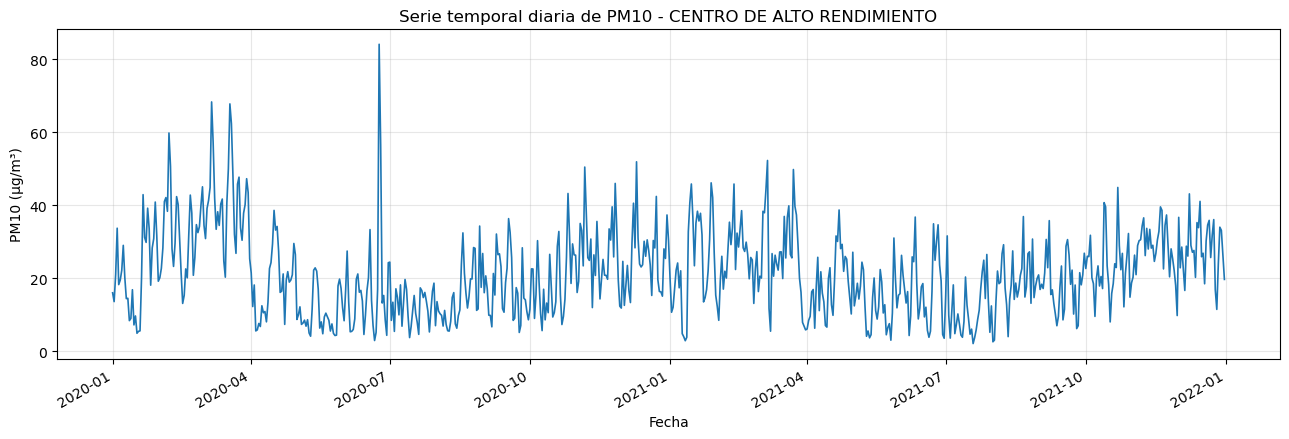

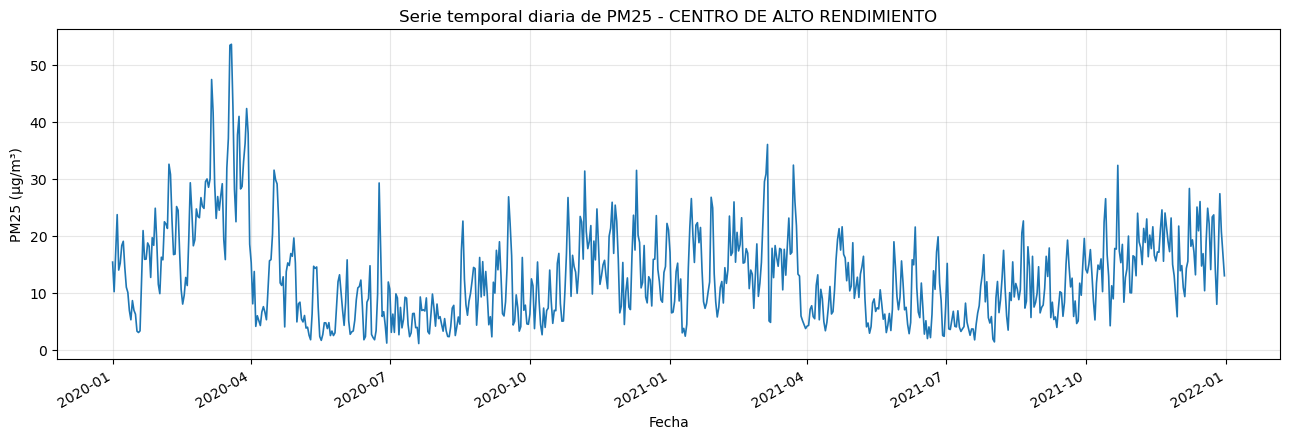

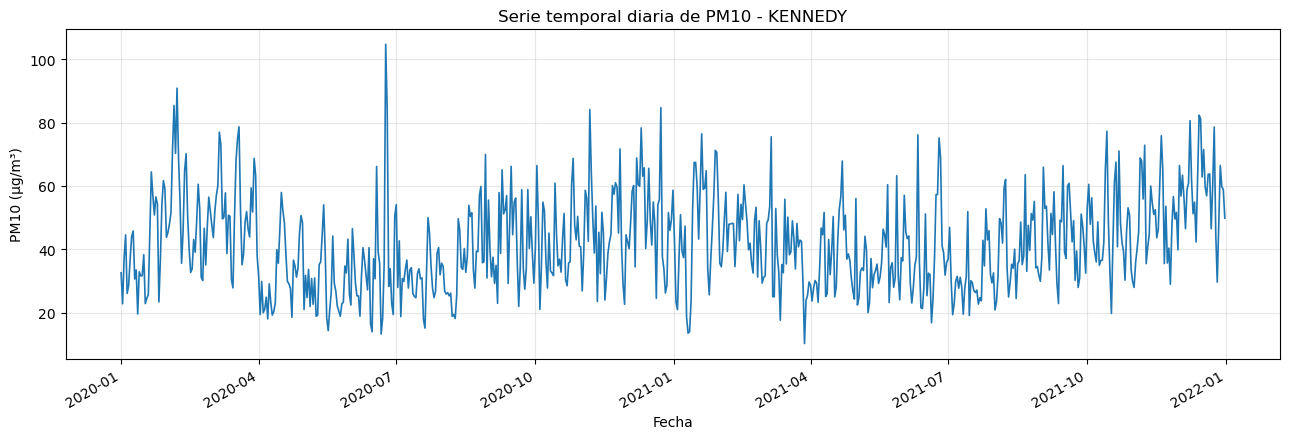

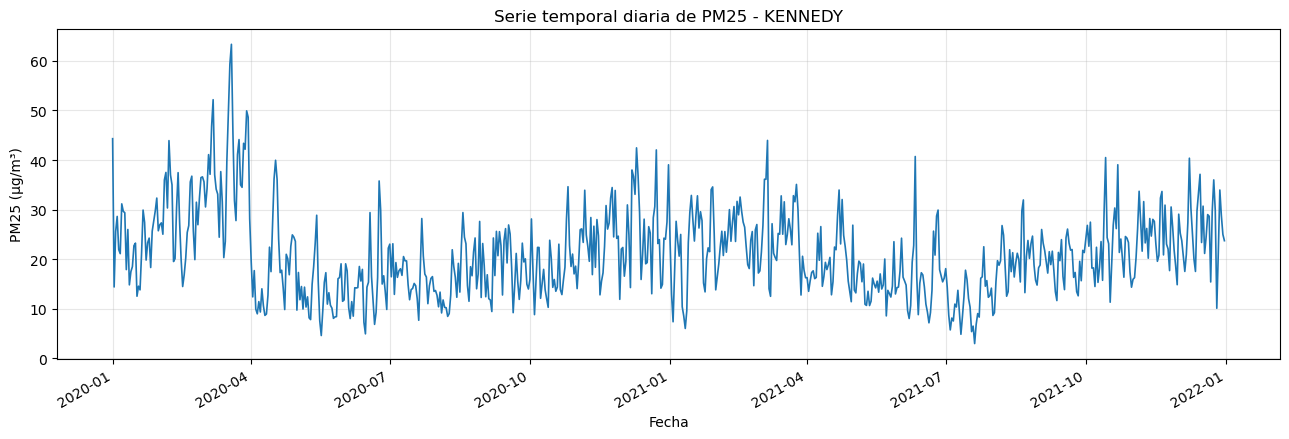

In [8]:

for est, g in df_master.groupby("Estacion"):
    g = g.sort_values("Fecha inicial")
    for target in ["PM10", "PM25"]:
        plot_serie_temporal(g, est, target, save=True)


## Modelo Random Forest actualizado

En esta versión se agregan los ajustes solicitados:

- particiones 90/10, 95/5, 85/15, **70/30** y **60/40**;
- horizontes fijos de 7, 30 y 90 días;
- selección de hiperparámetros con `TimeSeriesSplit`;
- hasta 5 folds cronológicos;
- cálculo del tiempo total de ejecución;
- gráfica de resta `Real - Predicción`;
- gráfica con el área de diferencia entre la serie real y la predicha;
- validación del cálculo de R² con fórmula manual y con `sklearn`.

In [9]:
# ============================================================
# CONFIGURACIÓN RANDOM FOREST ACTUALIZADA
# ============================================================

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 180)

# Base integrada del notebook
df_base_rf = df_master.copy()
df_base_rf["Fecha inicial"] = pd.to_datetime(df_base_rf["Fecha inicial"], errors="coerce")
df_base_rf = df_base_rf.dropna(subset=["Estacion", "Fecha inicial"])
df_base_rf = df_base_rf.sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

TARGET_CANDIDATES = ['PM10', 'PM25', 'PM2.5']
TARGETS_RF = [c for c in TARGET_CANDIDATES if c in df_base_rf.columns]

COVARIABLES_RF = [c for c in ['HAire2', 'TAire2', 'VViento', 'DViento'] if c in df_base_rf.columns]

OUT_DIR_RF = Path("salidas_01_RF_V3_60_70_TIEMPO_R2")
GRAF_DIR_RF = OUT_DIR_RF / "graficas"
TABLAS_DIR_RF = OUT_DIR_RF / "tablas"

GRAF_DIR_RF.mkdir(parents=True, exist_ok=True)
TABLAS_DIR_RF.mkdir(parents=True, exist_ok=True)

# Particiones porcentuales
# Nota: si la serie tiene 730 días, 70/30 equivale aproximadamente a 219 días de prueba,
# y 60/40 equivale aproximadamente a 292 días de prueba.
PARTICIONES_RF = [
    {"Tipo_evaluacion": "Porcentaje", "Escenario": "95_5",  "Entrenamiento_%": 95, "Prediccion_%": 5,  "train_size": 0.95},
    {"Tipo_evaluacion": "Porcentaje", "Escenario": "90_10", "Entrenamiento_%": 90, "Prediccion_%": 10, "train_size": 0.90},
    {"Tipo_evaluacion": "Porcentaje", "Escenario": "85_15", "Entrenamiento_%": 85, "Prediccion_%": 15, "train_size": 0.85},
    {"Tipo_evaluacion": "Porcentaje", "Escenario": "70_30", "Entrenamiento_%": 70, "Prediccion_%": 30, "train_size": 0.70},
    {"Tipo_evaluacion": "Porcentaje", "Escenario": "60_40", "Entrenamiento_%": 60, "Prediccion_%": 40, "train_size": 0.60},
]

# Horizontes fijos
HORIZONTES_RF = [
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_7_dias",  "Horizonte": "1 semana", "Dias_prueba": 7},
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_30_dias", "Horizonte": "1 mes",    "Dias_prueba": 30},
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_90_dias", "Horizonte": "3 meses",  "Dias_prueba": 90},
]

N_FOLDS_RF = 5
RANDOM_STATE_RF = 42

PARAM_GRID_RF = [
    {"n_estimators": 300, "max_depth": 5,    "min_samples_split": 2, "min_samples_leaf": 2, "max_features": "sqrt", "bootstrap": True},
    {"n_estimators": 500, "max_depth": 8,    "min_samples_split": 2, "min_samples_leaf": 2, "max_features": "sqrt", "bootstrap": True},
    {"n_estimators": 500, "max_depth": 10,   "min_samples_split": 4, "min_samples_leaf": 2, "max_features": 0.7,    "bootstrap": True},
    {"n_estimators": 700, "max_depth": 12,   "min_samples_split": 4, "min_samples_leaf": 3, "max_features": 0.7,    "bootstrap": True},
    {"n_estimators": 700, "max_depth": None, "min_samples_split": 6, "min_samples_leaf": 4, "max_features": 0.8,    "bootstrap": True},
]

display(Markdown("## Variables detectadas"))
display(pd.DataFrame({
    "Elemento": ["Targets", "Covariables"],
    "Valor": [str(TARGETS_RF), str(COVARIABLES_RF)]
}))

display(Markdown("## Particiones porcentuales"))
display(pd.DataFrame(PARTICIONES_RF))

display(Markdown("## Horizontes fijos"))
display(pd.DataFrame(HORIZONTES_RF))

display(Markdown("## Configuraciones candidatas Random Forest"))
display(pd.DataFrame(PARAM_GRID_RF))

## Variables detectadas

,Elemento,Valor
0,Targets,"['PM10', 'PM25']"
1,Covariables,"['HAire2', 'TAire2', 'VViento', 'DViento']"


## Particiones porcentuales

,Tipo_evaluacion,Escenario,Entrenamiento_%,Prediccion_%,train_size
0,Porcentaje,95_5,95,5,0.95
1,Porcentaje,90_10,90,10,0.90
2,Porcentaje,85_15,85,15,0.85
3,Porcentaje,70_30,70,30,0.70
4,Porcentaje,60_40,60,40,0.60


## Horizontes fijos

,Tipo_evaluacion,Escenario,Horizonte,Dias_prueba
0,Horizonte fijo,H_7_dias,1 semana,7
1,Horizonte fijo,H_30_dias,1 mes,30
2,Horizonte fijo,H_90_dias,3 meses,90


## Configuraciones candidatas Random Forest

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap
0,300,5.0,2,2,sqrt,True
1,500,8.0,2,2,sqrt,True
2,500,10.0,4,2,0.7,True
3,700,12.0,4,3,0.7,True
4,700,NaN,6,4,0.8,True


In [10]:
# ============================================================
# FUNCIONES RANDOM FOREST
# ============================================================

def nombre_seguro(texto):
    texto = str(texto)
    for ch in [" ", "/", "\\", ":", "*", "?", '"', "<", ">", "|", ".", ","]:
        texto = texto.replace(ch, "_")
    return texto


def calcular_metricas_validando_r2(y_real, y_pred):
    y_real = pd.Series(y_real).astype(float)
    y_pred = pd.Series(y_pred, index=y_real.index).astype(float)

    data = pd.concat([y_real.rename("real"), y_pred.rename("pred")], axis=1)
    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    if len(data) == 0:
        return {
            "MAE": np.nan, "RMSE": np.nan, "MAPE_%": np.nan, "sMAPE_%": np.nan,
            "R2": np.nan, "R2_manual": np.nan, "SS_res": np.nan, "SS_tot": np.nan,
            "Varianza_real": np.nan, "Media_real": np.nan, "N_eval": 0,
            "R2_diferencia_sklearn_manual": np.nan
        }

    mae = mean_absolute_error(data["real"], data["pred"])
    rmse = np.sqrt(mean_squared_error(data["real"], data["pred"]))
    r2_sklearn = r2_score(data["real"], data["pred"])

    ss_res = np.sum((data["real"] - data["pred"]) ** 2)
    ss_tot = np.sum((data["real"] - data["real"].mean()) ** 2)

    if ss_tot > 0:
        r2_manual = 1 - (ss_res / ss_tot)
    else:
        r2_manual = np.nan

    mask = np.abs(data["real"]) > 1e-9
    mape = np.mean(np.abs((data.loc[mask, "real"] - data.loc[mask, "pred"]) / data.loc[mask, "real"])) * 100 if mask.sum() > 0 else np.nan
    smape = np.mean(2 * np.abs(data["pred"] - data["real"]) / (np.abs(data["real"]) + np.abs(data["pred"]) + 1e-9)) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_%": mape,
        "sMAPE_%": smape,
        "R2": r2_sklearn,
        "R2_manual": r2_manual,
        "SS_res": ss_res,
        "SS_tot": ss_tot,
        "Varianza_real": data["real"].var(),
        "Media_real": data["real"].mean(),
        "N_eval": len(data),
        "R2_diferencia_sklearn_manual": abs(r2_sklearn - r2_manual) if pd.notna(r2_manual) else np.nan
    }


def crear_features_modelo(df_estacion, target, covariables):
    df = df_estacion.copy()
    df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")
    df = df.dropna(subset=["Fecha inicial"])

    cols_num = [c for c in [target] + covariables if c in df.columns]
    for c in cols_num:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # Promedio por fecha para evitar duplicados
    df = df[["Fecha inicial"] + cols_num].groupby("Fecha inicial", as_index=False).mean()
    df = df.sort_values("Fecha inicial").set_index("Fecha inicial").asfreq("D")

    df[cols_num] = df[cols_num].interpolate(method="time").bfill().ffill()

    df["dia_semana"] = df.index.dayofweek
    df["es_fin_semana"] = (df.index.dayofweek >= 5).astype(int)
    df["mes"] = df.index.month
    df["dia_anio"] = df.index.dayofyear
    df["dia_anio_sin"] = np.sin(2 * np.pi * df["dia_anio"] / 365)
    df["dia_anio_cos"] = np.cos(2 * np.pi * df["dia_anio"] / 365)
    df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12)
    df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12)

    if "DViento" in df.columns:
        df["DViento_sin"] = np.sin(np.deg2rad(df["DViento"]))
        df["DViento_cos"] = np.cos(np.deg2rad(df["DViento"]))

    for lag in [1, 2, 3, 7, 14, 21, 30]:
        df[f"{target}_lag_{lag}"] = df[target].shift(lag)

    for ventana in [3, 7, 14, 21, 30]:
        s = df[target].shift(1).rolling(ventana)
        df[f"{target}_media_{ventana}"] = s.mean()
        df[f"{target}_std_{ventana}"] = s.std()
        df[f"{target}_min_{ventana}"] = s.min()
        df[f"{target}_max_{ventana}"] = s.max()

    df[f"{target}_diff_1"] = df[target].shift(1) - df[target].shift(2)
    df[f"{target}_diff_7"] = df[target].shift(1) - df[target].shift(7)

    covs = covariables.copy()
    if "DViento_sin" in df.columns and "DViento_cos" in df.columns:
        covs += ["DViento_sin", "DViento_cos"]

    for cov in covs:
        if cov not in df.columns:
            continue
        for lag in [1, 2, 3, 7, 14]:
            df[f"{cov}_lag_{lag}"] = df[cov].shift(lag)
        for ventana in [3, 7, 14]:
            df[f"{cov}_media_{ventana}"] = df[cov].shift(1).rolling(ventana).mean()

    for prec in ["P", "PLiquida"]:
        if prec in df.columns:
            for ventana in [3, 7, 14]:
                df[f"{prec}_acum_{ventana}"] = df[prec].shift(1).rolling(ventana).sum()

    excluir = ["PM10", "PM25", "PM2.5"] + covariables
    features = [c for c in df.columns if c not in excluir]
    data = df[[target] + features].replace([np.inf, -np.inf], np.nan).dropna().copy()

    features = [c for c in features if c in data.columns and data[c].nunique(dropna=True) > 1]

    X = data[features]
    y = data[target]

    return X, y, features


def seleccionar_hiperparametros_rf(X_train, y_train, estacion, target, escenario):
    n_splits = min(N_FOLDS_RF, max(2, len(X_train) // 20))
    tscv = TimeSeriesSplit(n_splits=n_splits)
    resultados = []

    for id_config, params in enumerate(PARAM_GRID_RF):
        for fold, (idx_tr, idx_val) in enumerate(tscv.split(X_train), start=1):
            X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
            y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]

            modelo = RandomForestRegressor(**params, random_state=RANDOM_STATE_RF, n_jobs=-1)
            modelo.fit(X_tr, y_tr)

            pred = pd.Series(modelo.predict(X_val), index=y_val.index).clip(lower=0)
            met = calcular_metricas_validando_r2(y_val, pred)

            resultados.append({
                "Estacion": estacion, "Variable": target, "Escenario": escenario,
                "id_config": id_config, "Fold": fold, "n_splits_usados": n_splits,
                **params, "MAE": met["MAE"], "RMSE": met["RMSE"], "R2": met["R2"]
            })

    folds = pd.DataFrame(resultados)
    resumen = (
        folds.groupby("id_config", as_index=False)
        .agg(RMSE_validacion_media=("RMSE", "mean"),
             RMSE_validacion_std=("RMSE", "std"),
             MAE_validacion_media=("MAE", "mean"),
             R2_validacion_media=("R2", "mean"),
             n_splits_usados=("n_splits_usados", "first"))
        .sort_values(["RMSE_validacion_media", "RMSE_validacion_std"])
        .reset_index(drop=True)
    )

    for p in PARAM_GRID_RF[0].keys():
        resumen[p] = resumen["id_config"].apply(lambda i: PARAM_GRID_RF[int(i)][p])

    mejor_id = int(resumen.iloc[0]["id_config"])
    return PARAM_GRID_RF[mejor_id].copy(), resumen, folds

In [14]:
# ============================================================
# ENTRENAMIENTO Y EVALUACIÓN RANDOM FOREST
# ============================================================

def entrenar_evaluar_rf(X, y, estacion, target, tipo_evaluacion, escenario, train_size=None, dias_prueba=None):
    n = len(y)

    if tipo_evaluacion == "Porcentaje":
        n_train = int(n * train_size)
    else:
        if n <= dias_prueba + 30:
            return None
        n_train = n - dias_prueba

    if n_train < 30 or n_train >= n:
        return None

    X_train, X_test = X.iloc[:n_train], X.iloc[n_train:]
    y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]

    mejores_params, cv_resumen, cv_folds = seleccionar_hiperparametros_rf(X_train, y_train, estacion, target, escenario)

    modelo = RandomForestRegressor(**mejores_params, random_state=RANDOM_STATE_RF, n_jobs=-1)
    modelo.fit(X_train, y_train)

    pred_train = pd.Series(modelo.predict(X_train), index=y_train.index).clip(lower=0)
    pred_test = pd.Series(modelo.predict(X_test), index=y_test.index).clip(lower=0)

    met_train = calcular_metricas_validando_r2(y_train, pred_train)
    met_test = calcular_metricas_validando_r2(y_test, pred_test)

    filas_metricas = []
    for etapa, y_real, pred, met in [
        ("Entrenamiento", y_train, pred_train, met_train),
        ("Prueba", y_test, pred_test, met_test)
    ]:
        filas_metricas.append({
            "Estacion": estacion,
            "Variable": target,
            "Modelo": "Random Forest",
            "Tipo_evaluacion": tipo_evaluacion,
            "Escenario": escenario,
            "Etapa": etapa,
            "Fecha_inicio": y_real.index.min(),
            "Fecha_fin": y_real.index.max(),
            "N_registros": len(y_real),
            "Dias_prediccion": 0 if etapa == "Entrenamiento" else len(y_real),
            **met,
            **mejores_params
        })

    sobreajuste = {
        "Estacion": estacion,
        "Variable": target,
        "Tipo_evaluacion": tipo_evaluacion,
        "Escenario": escenario,
        "RMSE_entrenamiento": met_train["RMSE"],
        "RMSE_prueba": met_test["RMSE"],
        "Diferencia_RMSE": met_test["RMSE"] - met_train["RMSE"],
        "R2_entrenamiento": met_train["R2"],
        "R2_prueba": met_test["R2"],
        "Diferencia_R2_train_test": met_train["R2"] - met_test["R2"],
        "Dias_prueba": len(y_test),
        "Interpretacion": "Posible sobreajuste" if (met_train["R2"] - met_test["R2"]) > 0.30 else "Diferencia moderada"
    }

    importancia = pd.DataFrame({
        "Estacion": estacion,
        "Variable_objetivo": target,
        "Tipo_evaluacion": tipo_evaluacion,
        "Escenario": escenario,
        "Feature": X_train.columns,
        "Importancia": modelo.feature_importances_
    }).sort_values("Importancia", ascending=False)

    predicciones = pd.concat([
        pd.DataFrame({"Estacion": estacion, "Variable": target, "Tipo_evaluacion": tipo_evaluacion,
                      "Escenario": escenario, "Etapa": "Entrenamiento", "Fecha inicial": y_train.index,
                      "Real": y_train.values, "Prediccion": pred_train.values}),
        pd.DataFrame({"Estacion": estacion, "Variable": target, "Tipo_evaluacion": tipo_evaluacion,
                      "Escenario": escenario, "Etapa": "Prueba", "Fecha inicial": y_test.index,
                      "Real": y_test.values, "Prediccion": pred_test.values})
    ], ignore_index=True)

    predicciones["Error"] = predicciones["Real"] - predicciones["Prediccion"]
    predicciones["Error_abs"] = predicciones["Error"].abs()

    # Gráfica real vs predicción
    plt.figure(figsize=(13, 4))
    plt.plot(y_train.index, y_train.values, label="Real entrenamiento")
    plt.plot(pred_train.index, pred_train.values, label="Predicción entrenamiento")
    plt.plot(y_test.index, y_test.values, label="Real prueba")
    plt.plot(pred_test.index, pred_test.values, label="Predicción prueba")
    plt.axvline(y_test.index.min(), linestyle="--", label="Inicio prueba")
    plt.title(f"Random Forest - {tipo_evaluacion} {escenario} - {target} - {estacion}")
    plt.xlabel("Fecha")
    plt.ylabel(target)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(GRAF_DIR_RF / f"RF_prediccion_{tipo_evaluacion}_{escenario}_{target}_{nombre_seguro(estacion)}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

# ============================================================
# GRÁFICA MEJORADA DE RESTA: SOLO ERRORES RELEVANTES
# ============================================================

UMBRAL_ERROR = 1.0  # Puedes cambiarlo a 0.5, 1, 2, etc.

df_error = pd.DataFrame({
    "Real": y_test,
    "Prediccion": pred_test
})

df_error["Error"] = df_error["Real"] - df_error["Prediccion"]
df_error["Error_abs"] = df_error["Error"].abs()

# Se eliminan los días donde el error es cero o muy pequeño
df_error_filtrado = df_error[df_error["Error_abs"] > UMBRAL_ERROR].copy()

plt.figure(figsize=(13, 4))

plt.bar(
    df_error_filtrado.index,
    df_error_filtrado["Error"]
)

plt.axhline(0, linestyle="--", label="Error cero")

plt.title(
    f"Días con error relevante - Random Forest - {tipo_evaluacion} {escenario} - {target} - {estacion}"
)

plt.xlabel("Fecha")
plt.ylabel("Error = Real - Predicción")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()

nombre_error = (
    f"RF_error_filtrado_{tipo_evaluacion}_{escenario}_{target}_{nombre_seguro_rf(estacion)}.png"
)

plt.savefig(GRAF_DIR_RF / nombre_error, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# Tabla resumen de errores
resumen_error = pd.DataFrame([{
    "Estacion": estacion,
    "Variable": target,
    "Tipo_evaluacion": tipo_evaluacion,
    "Escenario": escenario,
    "Total_dias_prueba": len(df_error),
    "Dias_con_error_relevante": len(df_error_filtrado),
    "Dias_eliminados_por_error_bajo": len(df_error) - len(df_error_filtrado),
    "Umbral_error_usado": UMBRAL_ERROR,
    "Error_promedio": df_error["Error"].mean(),
    "Error_absoluto_promedio": df_error["Error_abs"].mean(),
    "Error_maximo_positivo": df_error["Error"].max(),
    "Error_maximo_negativo": df_error["Error"].min()
}])

display(Markdown("### Resumen de errores relevantes"))
display(resumen_error)
    # Gráfica con área de diferencia
    plt.figure(figsize=(13, 4))
    plt.plot(y_test.index, y_test.values, label="Real prueba")
    plt.plot(pred_test.index, pred_test.values, label="Predicción prueba")
    plt.fill_between(y_test.index, y_test.values, pred_test.reindex(y_test.index).values, alpha=0.25, label="Diferencia visual")
    plt.title(f"Comparativa con área de error - Random Forest - {tipo_evaluacion} {escenario} - {target} - {estacion}")
    plt.xlabel("Fecha")
    plt.ylabel(target)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(GRAF_DIR_RF / f"RF_area_error_{tipo_evaluacion}_{escenario}_{target}_{nombre_seguro(estacion)}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

    return {
        "metricas": filas_metricas,
        "sobreajuste": sobreajuste,
        "importancia": importancia,
        "predicciones": predicciones,
        "cv_resumen": cv_resumen.assign(Estacion=estacion, Variable=target, Escenario=escenario, Tipo_evaluacion=tipo_evaluacion),
        "cv_folds": cv_folds.assign(Tipo_evaluacion=tipo_evaluacion)
    }


metricas_rf = []
sobreajuste_rf = []
importancias_rf = []
predicciones_rf = []
cv_resumen_rf = []
cv_folds_rf = []

for estacion, df_estacion in df_base_rf.groupby("Estacion"):
    for target in TARGETS_RF:
        display(Markdown(f"# Random Forest para {target} - {estacion}"))

        X, y, features = crear_features_modelo(df_estacion, target, COVARIABLES_RF)

        display(pd.DataFrame({
            "Elemento": ["Registros disponibles", "Variables predictoras", "Fecha inicial", "Fecha final"],
            "Valor": [len(y), X.shape[1], y.index.min(), y.index.max()]
        }))

        escenarios = []
        escenarios.extend(PARTICIONES_RF)
        escenarios.extend(HORIZONTES_RF)

        for esc in escenarios:
            if esc["Tipo_evaluacion"] == "Porcentaje":
                resultado = entrenar_evaluar_rf(
                    X, y, estacion, target, "Porcentaje", esc["Escenario"],
                    train_size=esc["train_size"]
                )
            else:
                resultado = entrenar_evaluar_rf(
                    X, y, estacion, target, "Horizonte fijo", esc["Escenario"],
                    dias_prueba=esc["Dias_prueba"]
                )

            if resultado is None:
                print(f"No se pudo evaluar {target} - {estacion} - {esc['Escenario']} por pocos datos.")
                continue

            metricas_rf.extend(resultado["metricas"])
            sobreajuste_rf.append(resultado["sobreajuste"])
            importancias_rf.append(resultado["importancia"])
            predicciones_rf.append(resultado["predicciones"])
            cv_resumen_rf.append(resultado["cv_resumen"])
            cv_folds_rf.append(resultado["cv_folds"])

print("Modelado Random Forest finalizado.")

IndentationError: unexpected indent (1812139016.py, line 168)

In [12]:
# ============================================================
# TABLAS, COMPARATIVOS, TIEMPO Y VALIDACIÓN R²
# ============================================================

metricas_rf_df = pd.DataFrame(metricas_rf)
sobreajuste_rf_df = pd.DataFrame(sobreajuste_rf)
predicciones_rf_df = pd.concat(predicciones_rf, ignore_index=True) if predicciones_rf else pd.DataFrame()
importancias_rf_df = pd.concat(importancias_rf, ignore_index=True) if importancias_rf else pd.DataFrame()
cv_resumen_rf_df = pd.concat(cv_resumen_rf, ignore_index=True) if cv_resumen_rf else pd.DataFrame()
cv_folds_rf_df = pd.concat(cv_folds_rf, ignore_index=True) if cv_folds_rf else pd.DataFrame()

for df_tmp in [metricas_rf_df, sobreajuste_rf_df, cv_resumen_rf_df, cv_folds_rf_df]:
    if not df_tmp.empty:
        num_cols = df_tmp.select_dtypes(include=[np.number]).columns
        df_tmp[num_cols] = df_tmp[num_cols].round(4)

metricas_prueba_rf = metricas_rf_df[metricas_rf_df["Etapa"] == "Prueba"].copy()

mejor_escenario_rf = (
    metricas_prueba_rf
    .sort_values(["Estacion", "Variable", "RMSE"])
    .groupby(["Estacion", "Variable"], as_index=False)
    .first()
)

comparativo_promedio_rf = (
    metricas_prueba_rf
    .groupby(["Tipo_evaluacion", "Escenario"], as_index=False)
    .agg({
        "MAE": "mean", "RMSE": "mean", "MAPE_%": "mean", "sMAPE_%": "mean", "R2": "mean",
        "R2_manual": "mean", "N_registros": "sum", "Dias_prediccion": "mean"
    })
    .sort_values("RMSE")
)

validacion_r2_rf = metricas_rf_df[[
    "Estacion", "Variable", "Tipo_evaluacion", "Escenario", "Etapa", "N_registros",
    "RMSE", "R2", "R2_manual", "R2_diferencia_sklearn_manual",
    "SS_res", "SS_tot", "Varianza_real", "Media_real"
]].copy()

TIEMPO_FIN_TOTAL_GENERAL = time.perf_counter()
TIEMPO_TOTAL_SEGUNDOS = TIEMPO_FIN_TOTAL_GENERAL - TIEMPO_INICIO_TOTAL_GENERAL
TIEMPO_TOTAL_MINUTOS = TIEMPO_TOTAL_SEGUNDOS / 60

tiempo_df = pd.DataFrame([{
    "Modelo": "Random Forest",
    "Tiempo_total_segundos": TIEMPO_TOTAL_SEGUNDOS,
    "Tiempo_total_minutos": TIEMPO_TOTAL_MINUTOS
}])

display(Markdown("# Métricas Random Forest"))
display(metricas_rf_df)

display(Markdown("# Comparativo promedio por escenario"))
display(comparativo_promedio_rf)

display(Markdown("# Mejor escenario por estación y variable"))
display(mejor_escenario_rf)

display(Markdown("# Tabla para revisar sobreajuste"))
display(sobreajuste_rf_df)

display(Markdown("# Validación del cálculo de R²"))
display(validacion_r2_rf)

display(Markdown("# Tiempo total de ejecución"))
display(tiempo_df)

metricas_rf_df.to_csv(TABLAS_DIR_RF / "metricas_random_forest.csv", index=False, encoding="utf-8-sig")
comparativo_promedio_rf.to_csv(TABLAS_DIR_RF / "comparativo_promedio_random_forest.csv", index=False, encoding="utf-8-sig")
mejor_escenario_rf.to_csv(TABLAS_DIR_RF / "mejor_escenario_random_forest.csv", index=False, encoding="utf-8-sig")
sobreajuste_rf_df.to_csv(TABLAS_DIR_RF / "tabla_sobreajuste_random_forest.csv", index=False, encoding="utf-8-sig")
validacion_r2_rf.to_csv(TABLAS_DIR_RF / "validacion_R2_random_forest.csv", index=False, encoding="utf-8-sig")
tiempo_df.to_csv(TABLAS_DIR_RF / "tiempo_total_ejecucion_random_forest.csv", index=False, encoding="utf-8-sig")
cv_resumen_rf_df.to_csv(TABLAS_DIR_RF / "validacion_temporal_resumen_hiperparametros.csv", index=False, encoding="utf-8-sig")
cv_folds_rf_df.to_csv(TABLAS_DIR_RF / "validacion_temporal_detalle_folds.csv", index=False, encoding="utf-8-sig")

if not predicciones_rf_df.empty:
    predicciones_rf_df.to_csv(TABLAS_DIR_RF / "predicciones_random_forest.csv", index=False, encoding="utf-8-sig")

if not importancias_rf_df.empty:
    importancias_rf_df.to_csv(TABLAS_DIR_RF / "importancia_variables_random_forest.csv", index=False, encoding="utf-8-sig")

display(Markdown(
    "Nota metodológica: si `R2` y `R2_manual` coinciden, el cálculo está correcto. "
    "Si la gráfica visualmente parece buena pero el R² es bajo, puede deberse a baja variabilidad del periodo de prueba, "
    "a picos no capturados o a que el error es alto en relación con la varianza real."
))

# Métricas Random Forest

,Estacion,Variable,Modelo,Tipo_evaluacion,Escenario,Etapa,Fecha_inicio,Fecha_fin,N_registros,Dias_prediccion,MAE,RMSE,MAPE_%,sMAPE_%,R2,R2_manual,SS_res,SS_tot,Varianza_real,Media_real,N_eval,R2_diferencia_sklearn_manual,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap
0,CENTRO DE ALTO RENDIMIENTO,PM10,Random Forest,Porcentaje,95_5,Entrenamiento,2020-01-31,2021-11-25,665,0,2.8289,4.3398,19.2327,16.4470,0.8646,0.8646,12524.7104,92515.7967,139.3310,20.9205,665,0.0,700,NaN,6,4,0.8,True
1,CENTRO DE ALTO RENDIMIENTO,PM10,Random Forest,Porcentaje,95_5,Prueba,2021-11-26,2021-12-31,36,36,5.4819,6.7990,22.4937,21.1024,0.2056,0.2056,1664.1716,2094.9375,59.8554,27.0616,36,0.0,700,NaN,6,4,0.8,True
2,CENTRO DE ALTO RENDIMIENTO,PM10,Random Forest,Porcentaje,90_10,Entrenamiento,2020-01-31,2021-10-21,630,0,2.8675,4.3843,19.8091,16.9281,0.8636,0.8636,12109.8884,88766.6746,141.1235,20.5071,630,0.0,700,NaN,6,4,0.8,True
3,CENTRO DE ALTO RENDIMIENTO,PM10,Random Forest,Porcentaje,90_10,Prueba,2021-10-22,2021-12-31,71,71,5.0381,6.4429,19.8606,18.9234,0.2301,0.2301,2947.2562,3828.0562,54.6865,27.7028,71,0.0,700,NaN,6,4,0.8,True
4,CENTRO DE ALTO RENDIMIENTO,PM10,Random Forest,Porcentaje,85_15,Entrenamiento,2020-01-31,2021-09-16,595,0,2.9011,4.4175,20.0985,17.1632,0.8659,0.8659,11610.9535,86597.4658,145.7870,20.4827,595,0.0,700,NaN,6,4,0.8,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,KENNEDY,PM25,Random Forest,Horizonte fijo,H_7_dias,Prueba,2021-12-25,2021-12-31,7,7,4.4256,6.6382,29.1603,20.3285,0.1245,0.1245,308.4634,352.3357,58.7226,24.6949,7,0.0,500,10.0,4,2,0.7,True
60,KENNEDY,PM25,Random Forest,Horizonte fijo,H_30_dias,Entrenamiento,2020-01-31,2021-12-01,671,0,2.1455,2.8850,11.8848,11.1245,0.8887,0.8887,5584.9213,50187.5248,74.9068,20.6312,671,0.0,700,NaN,6,4,0.8,True
61,KENNEDY,PM25,Random Forest,Horizonte fijo,H_30_dias,Prueba,2021-12-02,2021-12-31,30,30,4.8332,6.3500,22.3964,19.1077,0.0831,0.0831,1209.6767,1319.2929,45.4929,26.0121,30,0.0,700,NaN,6,4,0.8,True
62,KENNEDY,PM25,Random Forest,Horizonte fijo,H_90_dias,Entrenamiento,2020-01-31,2021-10-02,611,0,2.1485,2.9274,12.1723,11.3314,0.8897,0.8897,5236.1254,47459.1679,77.8019,20.3499,611,0.0,700,NaN,6,4,0.8,True


# Comparativo promedio por escenario

,Tipo_evaluacion,Escenario,MAE,RMSE,MAPE_%,sMAPE_%,R2,R2_manual,N_registros,Dias_prediccion
3,Porcentaje,60_40,5.398475,6.813725,32.149225,26.255475,0.474825,0.474825,1124,281.0
4,Porcentaje,70_30,5.405300,6.867375,30.972450,25.427425,0.496675,0.496675,844,211.0
5,Porcentaje,85_15,5.749750,7.246650,22.286225,21.011150,0.256000,0.256000,424,106.0
6,Porcentaje,90_10,5.920650,7.332775,20.893100,19.977300,0.149850,0.149850,284,71.0
2,Horizonte fijo,H_90_dias,5.915500,7.455400,21.831525,20.848450,0.189600,0.189600,360,90.0
7,Porcentaje,95_5,6.392450,7.790800,22.337100,21.316475,0.053525,0.053525,144,36.0
0,Horizonte fijo,H_30_dias,6.670050,7.957800,22.428325,21.260075,0.002300,0.002300,120,30.0
1,Horizonte fijo,H_7_dias,6.692225,8.376975,31.637850,26.308850,-0.121575,-0.121575,28,7.0


# Mejor escenario por estación y variable

...

# Validación del cálculo de R²

,Estacion,Variable,Tipo_evaluacion,Escenario,Etapa,N_registros,RMSE,R2,R2_manual,R2_diferencia_sklearn_manual,SS_res,SS_tot,Varianza_real,Media_real
0,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,95_5,Entrenamiento,665,4.3398,0.8646,0.8646,0.0,12524.7104,92515.7967,139.3310,20.9205
1,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,95_5,Prueba,36,6.7990,0.2056,0.2056,0.0,1664.1716,2094.9375,59.8554,27.0616
2,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,90_10,Entrenamiento,630,4.3843,0.8636,0.8636,0.0,12109.8884,88766.6746,141.1235,20.5071
3,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,90_10,Prueba,71,6.4429,0.2301,0.2301,0.0,2947.2562,3828.0562,54.6865,27.7028
4,CENTRO DE ALTO RENDIMIENTO,PM10,Porcentaje,85_15,Entrenamiento,595,4.4175,0.8659,0.8659,0.0,11610.9535,86597.4658,145.7870,20.4827
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,KENNEDY,PM25,Horizonte fijo,H_7_dias,Prueba,7,6.6382,0.1245,0.1245,0.0,308.4634,352.3357,58.7226,24.6949
60,KENNEDY,PM25,Horizonte fijo,H_30_dias,Entrenamiento,671,2.8850,0.8887,0.8887,0.0,5584.9213,50187.5248,74.9068,20.6312
61,KENNEDY,PM25,Horizonte fijo,H_30_dias,Prueba,30,6.3500,0.0831,0.0831,0.0,1209.6767,1319.2929,45.4929,26.0121
62,KENNEDY,PM25,Horizonte fijo,H_90_dias,Entrenamiento,611,2.9274,0.8897,0.8897,0.0,5236.1254,47459.1679,77.8019,20.3499


# Tiempo total de ejecución

,Modelo,Tiempo_total_segundos,Tiempo_total_minutos
0,Random Forest,2366.41518,39.440253


Nota metodológica: si `R2` y `R2_manual` coinciden, el cálculo está correcto. Si la gráfica visualmente parece buena pero el R² es bajo, puede deberse a baja variabilidad del periodo de prueba, a picos no capturados o a que el error es alto en relación con la varianza real.